# FER-2013 Facial Emotion Recognition — Google Colab Notebook

This notebook consolidates **data loading, preprocessing, visualization, model creation, training, and evaluation** into a single runnable notebook for the FER-2013 dataset.

The dataset is downloaded remotely using the **kagglehub** API — no manual upload required.

## 1. Install and Import Dependencies

In [ ]:
%pip install -q kagglehub

import os
# Suppress TF info/warning logs and oneDNN messages before importing TF
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'          # 0=all, 1=no INFO, 2=no INFO+WARNING
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'

import glob
import random
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
from PIL import Image

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import KFold

from keras.models import Sequential
from keras.layers import (Conv2D, MaxPooling2D, BatchNormalization,
                           Dense, Input, Dropout, SpatialDropout2D,
                           GlobalAveragePooling2D)
from keras.layers import RandomZoom, RandomTranslation, RandomRotation, RandomFlip
from keras.layers import LeakyReLU
from keras.optimizers import Adam, SGD
from keras.optimizers.schedules import CosineDecayRestarts
from keras.regularizers import l2
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.losses import CategoricalCrossentropy
from keras.metrics import F1Score

## 2. Download and Extract FER-2013 Dataset

Downloads the dataset using `kagglehub`. The returned path points to a directory containing `train/` and `test/` subdirectories, each with 7 emotion-named folders of 48×48 grayscale JPG images.

In [2]:
import kagglehub

# Download the FER-2013 image dataset (folder-structured version)
DATASET_PATH = kagglehub.dataset_download("msambare/fer2013")
print("Dataset downloaded to:", DATASET_PATH)

# Verify directory structure
for root, dirs, files in os.walk(DATASET_PATH):
    depth = root.replace(DATASET_PATH, "").count(os.sep)
    indent = " " * 2 * depth
    print(f"{indent}{os.path.basename(root)}/")
    if depth >= 2:  # only show counts for emotion folders
        print(f"{indent}  ({len(files)} images)")
        continue
    
import tensorflow as tf
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42

def set_seeds(seed: int = SEED) -> None:
    """Fix all relevant RNG seeds for reproducible runs."""
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds()
print(f"Global seed set to {SEED}.")


Using Colab cache for faster access to the 'fer2013' dataset.
Dataset downloaded to: /kaggle/input/fer2013
fer2013/
  test/
    surprise/
      (831 images)
    fear/
      (1024 images)
    angry/
      (958 images)
    neutral/
      (1233 images)
    sad/
      (1247 images)
    disgust/
      (111 images)
    happy/
      (1774 images)
  train/
    surprise/
      (3171 images)
    fear/
      (4097 images)
    angry/
      (3995 images)
    neutral/
      (4965 images)
    sad/
      (4830 images)
    disgust/
      (436 images)
    happy/
      (7215 images)
Num GPUs Available:  1
Global seed set to 42.


## 3. Define Constants and Data Loading Functions

In [3]:
# Emotion labels sorted alphabetically to ensure consistent integer encoding
LABELS = sorted(["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"])
LABEL_TO_IDX = {label: idx for idx, label in enumerate(LABELS)}
print("Labels:", LABELS)
print("Label → Index:", LABEL_TO_IDX)


def _load_split(split_dir: str):
    """
    Load all images from a split directory (train or test).

    Directory structure expected:
        split_dir/
            {emotion_class}/
                *.jpg

    Returns:
        X : np.ndarray of shape (N, 48, 48, 1), dtype float32, values in [0, 1]
        y : np.ndarray of shape (N, num_classes), dtype float32 — one-hot encoded labels
    """
    images = []
    labels = []

    for label in LABELS:
        class_dir = os.path.join(split_dir, label)
        if not os.path.isdir(class_dir):
            continue
        for img_path in glob.glob(os.path.join(class_dir, "*.jpg")):
            img = Image.open(img_path).convert("L")  # grayscale
            arr = np.array(img, dtype=np.float32) / 255.0  # normalize to [0, 1]
            images.append(arr)
            labels.append(LABEL_TO_IDX[label])

    X = np.array(images, dtype=np.float32)[..., np.newaxis]  # (N, 48, 48, 1)
    y_idx = np.array(labels, dtype=np.int64)
    y = np.eye(len(LABELS), dtype=np.float32)[y_idx]         # one-hot
    return X, y


def load_training_dataset():
    """Load the training split from the kagglehub download path."""
    train_dir = os.path.join(DATASET_PATH, "train")
    return _load_split(train_dir)


def load_testing_dataset():
    """Load the testing split from the kagglehub download path."""
    test_dir = os.path.join(DATASET_PATH, "test")
    return _load_split(test_dir)

Labels: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Label → Index: {'angry': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6}


## 4. Load Training and Testing Datasets

Loading Training Data...
Loading Testing Data...

X_train shape: (28709, 48, 48, 1)  |  Y_train shape: (28709, 7)
X_test  shape: (7178, 48, 48, 1)  |  Y_test  shape: (7178, 7)


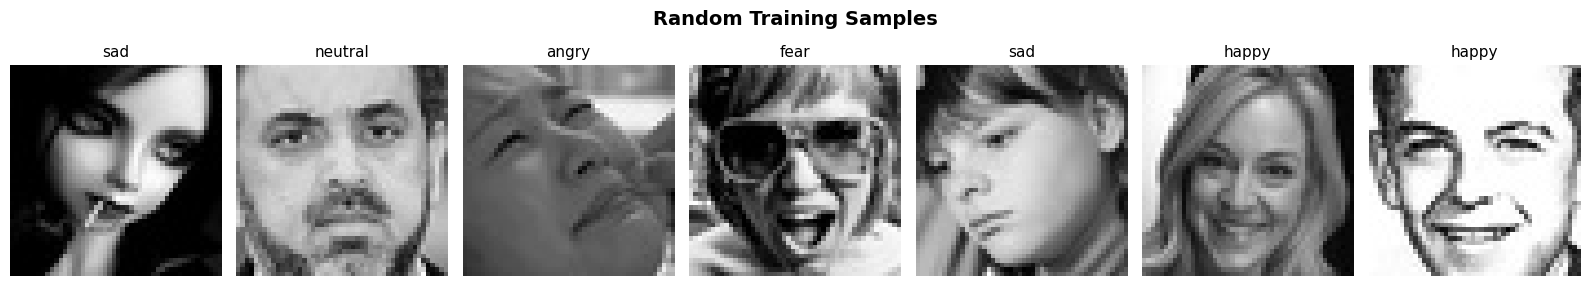

In [4]:
print("Loading Training Data...")
X_train, Y_train = load_training_dataset()
print("Loading Testing Data...")
X_test, Y_test = load_testing_dataset()

print(f"\nX_train shape: {X_train.shape}  |  Y_train shape: {Y_train.shape}")
print(f"X_test  shape: {X_test.shape}  |  Y_test  shape: {Y_test.shape}")

# Display a few sample images
fig, axes = plt.subplots(1, 7, figsize=(16, 3))
for i, ax in enumerate(axes):
    idx = np.random.randint(0, X_train.shape[0])
    ax.imshow(X_train[idx].squeeze(), cmap="gray")
    ax.set_title(LABELS[np.argmax(Y_train[idx])], fontsize=11)
    ax.axis("off")
fig.suptitle("Random Training Samples", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 5. Plot Class Distribution

/tmp/ipython-input-1057284687.py:28: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  Rectangle((0, 0), 1, 1, color=colors[i], edgecolor="black", linewidth=0.8)


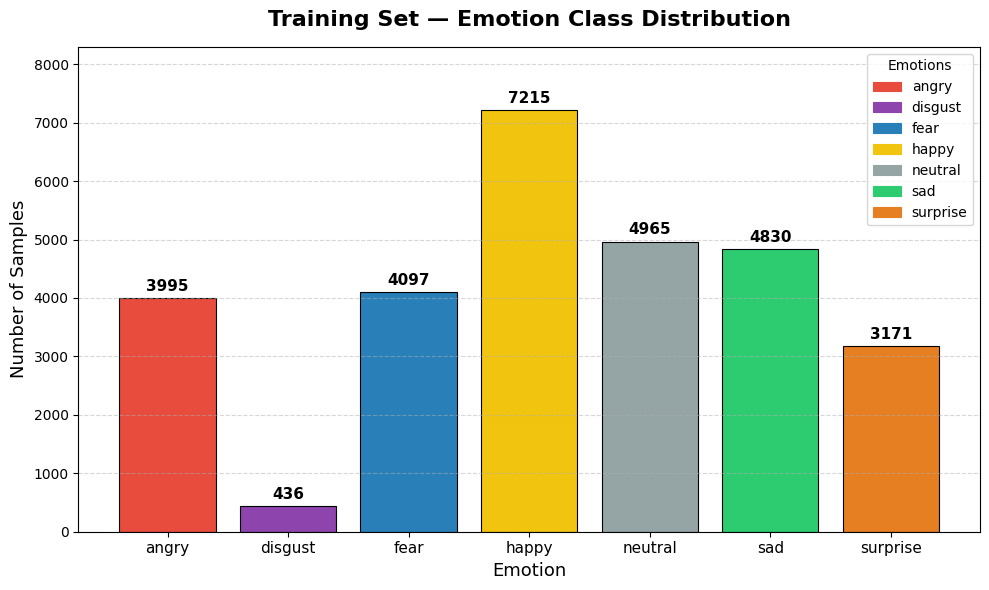

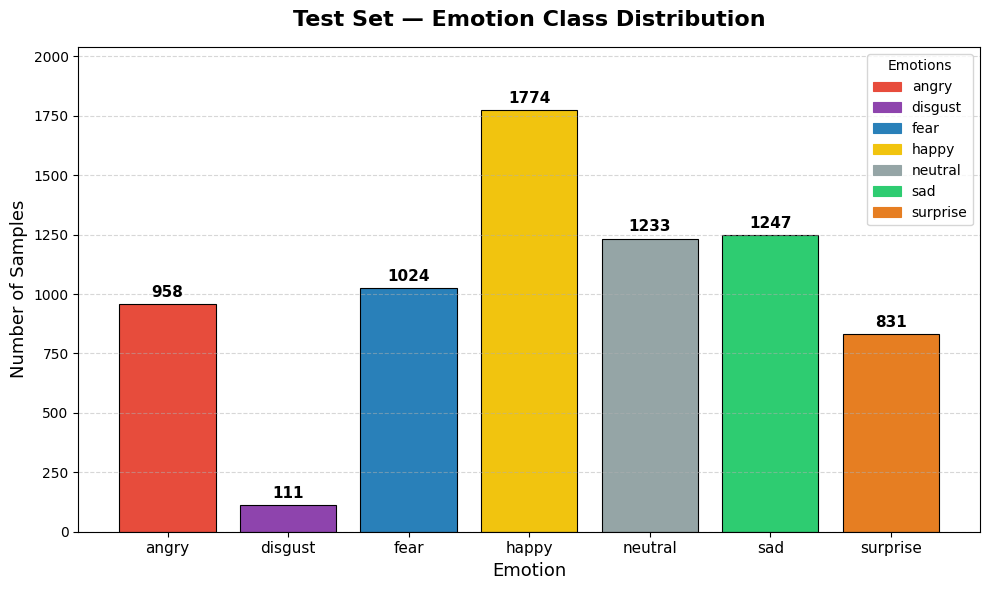

In [5]:
def plot_class_distribution(y: np.ndarray, title: str = "Emotion Class Distribution") -> None:
    """
    Plot a bar chart showing the number of samples per emotion class.

    Args:
        y     : np.ndarray of shape (N, num_classes) — one-hot encoded labels
        title : title of the plot
    """
    counts = y.sum(axis=0).astype(int)

    colors = ["#e74c3c", "#8e44ad", "#2980b9", "#f1c40f",
              "#95a5a6", "#2ecc71", "#e67e22"]

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.bar(LABELS, counts, color=colors, edgecolor="black", linewidth=0.8)

    # Annotate each bar with its sample count
    for bar, count in zip(bars, counts):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(counts) * 0.01,
            str(count),
            ha="center", va="bottom", fontsize=11, fontweight="bold",
        )

    # Legend mapping each color to its emotion
    legend_handles = [
        Rectangle((0, 0), 1, 1, color=colors[i], edgecolor="black", linewidth=0.8)
        for i in range(len(LABELS))
    ]
    ax.legend(legend_handles, LABELS, title="Emotions", loc="upper right", fontsize=10)

    ax.set_title(title, fontsize=16, fontweight="bold", pad=15)
    ax.set_xlabel("Emotion", fontsize=13)
    ax.set_ylabel("Number of Samples", fontsize=13)
    ax.set_ylim(0, max(counts) * 1.15)
    ax.tick_params(axis="x", labelsize=11)
    ax.grid(axis="y", linestyle="--", alpha=0.5)

    plt.tight_layout()
    plt.show()


plot_class_distribution(Y_train, "Training Set — Emotion Class Distribution")
plot_class_distribution(Y_test, "Test Set — Emotion Class Distribution")

## 6. Compute Class Weights

Use balanced class weights to handle the imbalanced emotion distribution. Each weight is capped at `max_weight` to prevent extreme values.

In [6]:
def get_class_weights(y: np.ndarray, max_weight: float):
    """
    Compute balanced class weights from one-hot labels, capped at max_weight.

    Args:
        y          : np.ndarray of shape (N, num_classes) — one-hot encoded labels
        max_weight : maximum allowed weight per class
    Returns:
        dict mapping class index → weight
    """
    y_integers = np.argmax(y, axis=1)
    weights = compute_class_weight(
        class_weight='balanced',
        classes=np.unique(y_integers),
        y=y_integers
    )
    return {idx: min(weight, max_weight) for idx, weight in enumerate(weights)}


class_weights = get_class_weights(Y_train, max_weight=4)
print("Class weights:")
for idx, w in class_weights.items():
    print(f"  {LABELS[idx]:>8s} (class {idx}): {w:.4f}")

Class weights:
     angry (class 0): 1.0266
   disgust (class 1): 4.0000
      fear (class 2): 1.0010
     happy (class 3): 0.5684
   neutral (class 4): 0.8260
       sad (class 5): 0.8491
  surprise (class 6): 1.2934


## 7. Build the CNN Model

Architecture:
- **Data Augmentation**: RandomZoom, RandomTranslation, RandomRotation, RandomFlip
- **4 Convolutional Blocks**: 64 → 128 → 256 → 512 filters (at `scale=1.0`), each with Conv2D (3×3, same padding, L2) → BatchNorm → LeakyReLU → MaxPool
- **Global Average Pooling Head**: GAP → Dropout → Dense(7, softmax)

The `scale` parameter dynamically controls model width — `scale=1.0` gives the default architecture, smaller values (e.g. `0.5`) produce a lightweight proxy suitable for hyperparameter search.

In [ ]:
def create_model(dropout_rate: float = 0.4, l2_lambda: float = 0.01,
                 learning_rate: float = 0.0001, optimizer=None,
                 scale: float = 1.0, num_classes: int = 7,
                 input_shape: tuple = (48, 48, 1)) -> Sequential:
    """
    Build, compile, and return a dynamically-scaled CNN with Global Average Pooling.

    Args:
        dropout_rate  : dropout probability before the output layer
        l2_lambda     : L2 regularization strength on Conv2D and Dense layers
        learning_rate : Adam optimizer learning rate (used when optimizer is None)
        optimizer     : keras optimizer instance; if None, defaults to Adam(learning_rate)
        scale         : width multiplier for convolutional filters
                        1.0 → base filters [64, 128, 256, 512]  (full model)
                        0.5 → halved   [32, 64, 128, 256]       (proxy for HP search)
        num_classes   : number of output classes
        input_shape   : spatial input shape
    """
    set_seeds()

    # Scale filter counts, rounded to nearest multiple of 8 for GPU efficiency
    def _f(base):
        return max(8, int(base * scale) // 8 * 8)

    f1, f2, f3, f4 = _f(64), _f(128), _f(256), _f(512)

    model = Sequential([
        Input(shape=input_shape),

        ## Data Augmentation
        RandomZoom(height_factor=(-0.1, 0.1)),
        RandomTranslation(height_factor=(-0.1, 0.1), width_factor=(-0.1, 0.1)),
        RandomRotation(factor=(-0.1, 0.1)),
        RandomFlip("horizontal"),

        ## Block 1
        Conv2D(f1, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        Conv2D(f1, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        MaxPooling2D((2, 2), strides=(2, 2)),

        ## Block 2
        Conv2D(f2, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        Conv2D(f2, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        Conv2D(f2, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        MaxPooling2D((2, 2), strides=(2, 2)),

        ## Block 3
        Conv2D(f3, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        Conv2D(f3, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        Conv2D(f3, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        MaxPooling2D((2, 2), strides=(2, 2)),
        SpatialDropout2D(0.1),

        ## Block 4
        Conv2D(f4, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        Conv2D(f4, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        Conv2D(f4, (3, 3), padding='same', use_bias=True, kernel_regularizer=l2(l2_lambda)),
        BatchNormalization(),
        LeakyReLU(negative_slope=0.01),
        MaxPooling2D((2, 2), strides=(2, 2)),
        SpatialDropout2D(0.25),

        ## Head — Global Average Pooling (replaces Flatten + Dense FC layers)
        GlobalAveragePooling2D(),
        Dropout(dropout_rate),
        Dense(num_classes, activation='softmax', kernel_regularizer=l2(l2_lambda)),
    ])

    if optimizer is None:
        optimizer = Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss=CategoricalCrossentropy(label_smoothing=0.1),
        metrics=[
            "accuracy",
            F1Score(average='weighted', name='f1_score'),
        ]
    )
    return model

## 8. Hyperparameter Optimization

This section fine-tunes the model's hyperparameters in three stages:
- **8a** — Build a stratified subset of the training data for faster search
- **8b** — Summary of prior findings from random search & K-fold cross-validation
- **8c** — Intelligent Bayesian optimization with **Optuna** (Hyperband pruning) to find the best dropout rate, L2 lambda, and learning rate

### 8a. Stratified Subset for Faster Search

Create a **25% stratified sample** of the training set that preserves the original class distribution. This smaller subset is used for all hyperparameter searches to speed up experimentation while keeping results representative.

In [ ]:
# ── Stratified subset for hyperparameter search ──────────────────────────────
from sklearn.model_selection import StratifiedShuffleSplit

SUBSET_FRACTION = 0.25        # fraction of training data used for the search
K_FOLDS         = 4

y_labels = np.argmax(Y_train, axis=1)  # one-hot → integer labels

sss = StratifiedShuffleSplit(n_splits=1, train_size=SUBSET_FRACTION, random_state=SEED)
subset_idx, _ = next(sss.split(X_train, y_labels))

X_search = X_train[subset_idx]
Y_search = Y_train[subset_idx]

print(f"Full training set : {len(X_train)} samples")
print(f"Search subset     : {len(X_search)} samples ({SUBSET_FRACTION*100:.0f}%)")
print(f"K-Folds           : {K_FOLDS}")
print("\nClass distribution (subset vs full):")
subset_labels = np.argmax(Y_search, axis=1)
for cls in np.unique(y_labels):
    full_pct   = np.mean(y_labels == cls) * 100
    subset_pct = np.mean(subset_labels == cls) * 100
    print(f"  class {cls} ({LABELS[cls]:>8s}): full={full_pct:.1f}%  subset={subset_pct:.1f}%")

### 8b. Prior Findings — Random Search & K-Fold Cross-Validation

A previous manual exploration using **random search with 4-fold cross-validation** on a 25 % stratified subset yielded the following insights:

| Hyperparameter | Best Range | Best Point Estimate |
|---|---|---|
| **Batch size** | 64 (clear winner) | 64 |
| **Learning rate** | 1 × 10⁻⁴ – 3 × 10⁻⁴ | 1 × 10⁻⁴ |
| **Dropout rate** | 0.3 – 0.7 (broad sweet spot) | 0.4 |
| **L2 lambda** | 0.005 – 0.05 | 0.01 |

These ranges achieved **≈ 67 % validation accuracy** on the full model and are used below to constrain the Optuna search space, ensuring we explore only the most promising region.

In [ ]:
# ── Install Optuna ────────────────────────────────────────────────────────────
%pip install -q optuna optuna-dashboard plotly

import optuna
from optuna.pruners import HyperbandPruner
from sklearn.model_selection import train_test_split

print(f"Optuna version: {optuna.__version__}")

### 8c. Optuna Bayesian Optimization with Hyperband Pruning

We use [Optuna](https://optuna.org/) to intelligently search for the best **dropout rate**, **L2 lambda**, and **learning rate**, constrained to the promising ranges identified in §8b.

**Design choices:**
- **Proxy model (`scale=0.5`)** — Halves the convolutional filter widths (64→32, 128→64, 256→128, 512→256), reducing trainable parameters by ≈ 4×. This dramatically speeds up each trial while preserving the relative ranking of hyperparameter configurations, because the bottleneck for generalization in this CNN is regularization strength (dropout, L2), not raw capacity.
- **Stratified 25 % subset** (from §8a) — Preserves class distribution while cutting per-epoch time.
- **Batch size fixed at 64** — Already established as optimal; not re-searched.
- **HyperbandPruner** — Aggressively prunes under-performing trials at early epochs (rungs at epochs 3 and 9), allocating more compute budget to promising configurations.
- **SQLite storage** — Persists all trial data so results survive kernel restarts and can be visualized with `optuna-dashboard` locally, or inspected with the inline Plotly charts below on Kaggle/Colab.

In [ ]:
# ── Optuna hyperparameter search ──────────────────────────────────────────────
from optuna.integration import TFKerasPruningCallback

OPTUNA_EPOCHS  = 20   # max epochs per trial (proxy model)
OPTUNA_BATCH   = 64
N_TRIALS       = 30

# Fixed train / val split from the stratified subset (done once, reused by all trials)
X_opt_train, X_opt_val, Y_opt_train, Y_opt_val = train_test_split(
    X_search, Y_search,
    test_size=0.2,
    stratify=np.argmax(Y_search, axis=1),
    random_state=SEED,
)

# Class weights for the Optuna training split
_y_int = np.argmax(Y_opt_train, axis=1)
_weights = compute_class_weight('balanced', classes=np.unique(_y_int), y=_y_int)
optuna_class_weights = {idx: min(w, 4.0) for idx, w in enumerate(_weights)}

print(f"Optuna train : {len(X_opt_train)} samples")
print(f"Optuna val   : {len(X_opt_val)} samples")


# ── Objective function ────────────────────────────────────────────────────────
def objective(trial: optuna.Trial) -> float:
    """Train a half-width proxy model and return the best validation loss."""
    dropout_rate  = trial.suggest_float("dropout_rate",  0.3,  0.7)
    l2_lambda     = trial.suggest_float("l2_lambda",     1e-3, 0.1,  log=True)
    learning_rate = trial.suggest_float("learning_rate", 5e-5, 5e-4, log=True)

    set_seeds()
    proxy = create_model(
        dropout_rate=dropout_rate,
        l2_lambda=l2_lambda,
        learning_rate=learning_rate,
        scale=0.5,          # lightweight proxy — ~4x fewer params
    )

    h = proxy.fit(
        X_opt_train, Y_opt_train,
        batch_size=OPTUNA_BATCH,
        epochs=OPTUNA_EPOCHS,
        class_weight=optuna_class_weights,
        validation_data=(X_opt_val, Y_opt_val),
        shuffle=True,
        verbose=0,
        callbacks=[TFKerasPruningCallback(trial, "val_loss")],
    )

    return min(h.history["val_loss"])


# ── Create study with SQLite storage + Hyperband pruner ──────────────────────
storage = optuna.storages.RDBStorage(
    url="sqlite:///optuna_fer2013.db",
    engine_kwargs={"connect_args": {"timeout": 30}},
)

study = optuna.create_study(
    study_name="fer2013_hpo",
    direction="minimize",
    pruner=HyperbandPruner(
        min_resource=3,              # earliest pruning rung (epoch 3)
        max_resource=OPTUNA_EPOCHS,  # latest rung (epoch 20)
        reduction_factor=3,          # keep top 1/3 at each rung
    ),
    storage=storage,
    load_if_exists=True,
)

print("Starting Optuna optimization ...")
study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)

# ── Print results ─────────────────────────────────────────────────────────────
print(f"\n{'='*60}")
print(f"Best trial : #{study.best_trial.number}")
print(f"  val_loss = {study.best_trial.value:.4f}")
for k, v in study.best_trial.params.items():
    print(f"  {k:14s} = {v}")
print('=' * 60)

In [ ]:
# ── Optuna Visualizations (inline — works on Kaggle / Colab) ─────────────────
# These use Plotly and render directly inside the notebook output cell.
import optuna.visualization as vis

fig_history = vis.plot_optimization_history(study)
fig_history.show()

fig_importance = vis.plot_param_importances(study)
fig_importance.show()

fig_parallel = vis.plot_parallel_coordinate(study)
fig_parallel.show()

fig_contour = vis.plot_contour(study, params=["dropout_rate", "l2_lambda"])
fig_contour.show()

# ── Optional: launch Optuna Dashboard (local environments only) ──────────────
# If running locally (not Kaggle/Colab), you can start the full interactive
# dashboard by uncommenting the line below.  It reads from the same SQLite DB:
#
#   !optuna-dashboard sqlite:///optuna_fer2013.db --port 8080
#
# Then open http://127.0.0.1:8080 in your browser.
# On Kaggle / Colab the inline Plotly charts above provide equivalent insight.

### 8d. Migrate Best Hyperparameters to Full Model

Extract the winning configuration from the Optuna study and assign it to the variables consumed by the training cell (§9). The batch size remains fixed at **64**.

In [ ]:
# ── Migrate best hyperparameters to full model ────────────────────────────────
BEST_BATCH_SIZE = 64   # fixed — not searched
BEST_DROPOUT    = study.best_trial.params["dropout_rate"]
BEST_L2_LAMBDA  = study.best_trial.params["l2_lambda"]
BEST_LR         = study.best_trial.params["learning_rate"]
EPOCHS          = 100

print("Best hyperparameters for full training (from Optuna):")
print(f"  batch_size    = {BEST_BATCH_SIZE}")
print(f"  dropout_rate  = {BEST_DROPOUT:.4f}")
print(f"  l2_lambda     = {BEST_L2_LAMBDA:.6f}")
print(f"  learning_rate = {BEST_LR:.6f}")
print(f"  epochs        = {EPOCHS}")

## 9. Train the Model (Full Run)

In [ ]:
# ── Learning-rate schedule: Cosine Decay with Warm Restarts ──────────────────
# ~28,709 train samples / batch_size=64 -> ~449 steps/epoch
# first_decay_steps = 15 epochs worth of steps (restart cycle length)
STEPS_PER_EPOCH    = len(X_train) // BEST_BATCH_SIZE
FIRST_DECAY_STEPS  = STEPS_PER_EPOCH * 15      # restart every 15 epochs
T_MUL              = 2.0                        # double the cycle length after each restart
M_MUL              = 0.9                        # slightly reduce peak LR each restart
ALPHA              = 1e-6                       # minimum LR at the bottom of each cosine cycle

lr_schedule = CosineDecayRestarts(
    initial_learning_rate=BEST_LR,
    first_decay_steps=FIRST_DECAY_STEPS,
    t_mul=T_MUL,
    m_mul=M_MUL,
    alpha=ALPHA,
)

# ── Optimizer: SGD with momentum ─────────────────────────────────────────────
optimizer = SGD(
    learning_rate=BEST_LR,
    momentum=0.9,
    nesterov=True,
)

# ── Create model with best hyperparameters (full scale) ─────────────────────
set_seeds()
model = create_model(
    dropout_rate=BEST_DROPOUT,
    l2_lambda=BEST_L2_LAMBDA,
    optimizer=optimizer,
    scale=1.0,   # full model
)
model.summary()

# ── Callbacks ────────────────────────────────────────────────────────────────
early_stopping_callback = EarlyStopping(
    patience=20,
    restore_best_weights=True,
    verbose=1,
)

# ── Train ────────────────────────────────────────────────────────────────────
print("Commencing Training...")
history = model.fit(
    x=X_train, y=Y_train,
    batch_size=BEST_BATCH_SIZE,
    epochs=EPOCHS,
    class_weight=class_weights,
    validation_data=(X_test, Y_test),
    shuffle=True,
    callbacks=[early_stopping_callback],
)

print("Training complete.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_zoom (RandomZoom)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 48, 48, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 48, 48, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 24, 24, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 24, 24, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 10,423,111 (39.76 MB)

 Trainable params: 10,415,431 (39.73 MB)

 Non-trainable params: 7,680 (30.00 KB)

Commencing Training...
Epoch 1/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 67s 111ms/step - accuracy: 0.1767 - f1_score: 0.1778 - loss: 16.2489 - val_accuracy: 0.2497 - val_f1_score: 0.1424 - val_loss: 15.4945
Epoch 2/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 49s 109ms/step - accuracy: 0.2071 - f1_score: 0.2085 - loss: 15.3429 - val_accuracy: 0.2704 - val_f1_score: 0.2653 - val_loss: 14.7294
Epoch 3/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 50s 111ms/step - accuracy: 0.2349 - f1_score: 0.2346 - loss: 14.5602 - val_accuracy: 0.2920 - val_f1_score: 0.2859 - val_loss: 14.0329
Epoch 4/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 51s 113ms/step - accuracy: 0.2484 - f1_score: 0.2470 - loss: 13.8516 - val_accuracy: 0.2811 - val_f1_score: 0.2639 - val_loss: 13.3985
Epoch 5/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 51s 113ms/step - accuracy: 0.2641 - f1_score: 0.2615 - loss: 13.1755 - val_accuracy: 0.3093 - val_f1_score: 0.2991 - val_loss: 12.7592
Epoch 6/100
449/449 ━━━━━━━━━━━━━━━━━━━━ 51s 113ms/step - accuracy: 0.2727 - f1_score: 0.2707 - l

## 9. Save Model Architecture and Weights

Saves the architecture as JSON and the weights as HDF5. Optionally downloads both files to your local machine via Colab's `files.download()`.

In [ ]:
# Save architecture to JSON
model_json = model.to_json()
with open("model.json", "w", encoding="utf-8") as json_file:
    json_file.write(model_json)

# Save weights
model.save_weights("model.weights.h5")

print("Saved model architecture to model.json")
print("Saved model weights  to model.weights.h5")

# (Optional) Download files to your local machine when running on Colab
try:
    from google.colab import files
    files.download("model.json")
    files.download("model.weights.h5")
except ImportError:
    print("Not running on Colab — skipping automatic download.")

## 10. Generate Confusion Matrices

Evaluate the model on both training and test sets with heatmap confusion matrices showing per-class predictions and overall accuracy.


--- Generating: Validation Matrix on Training ---
898/898 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step


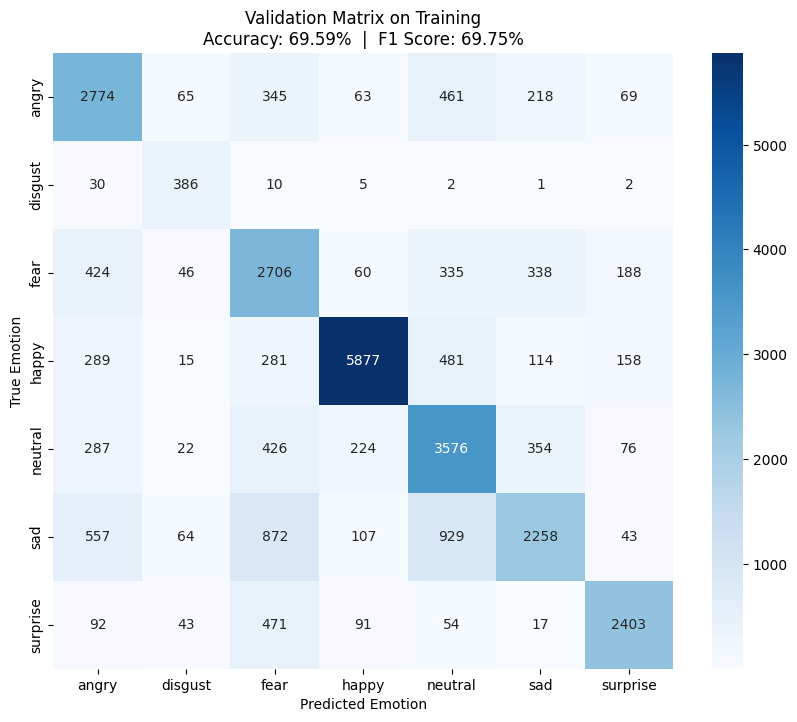


--- Generating: Validation Matrix on Testing ---
225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step


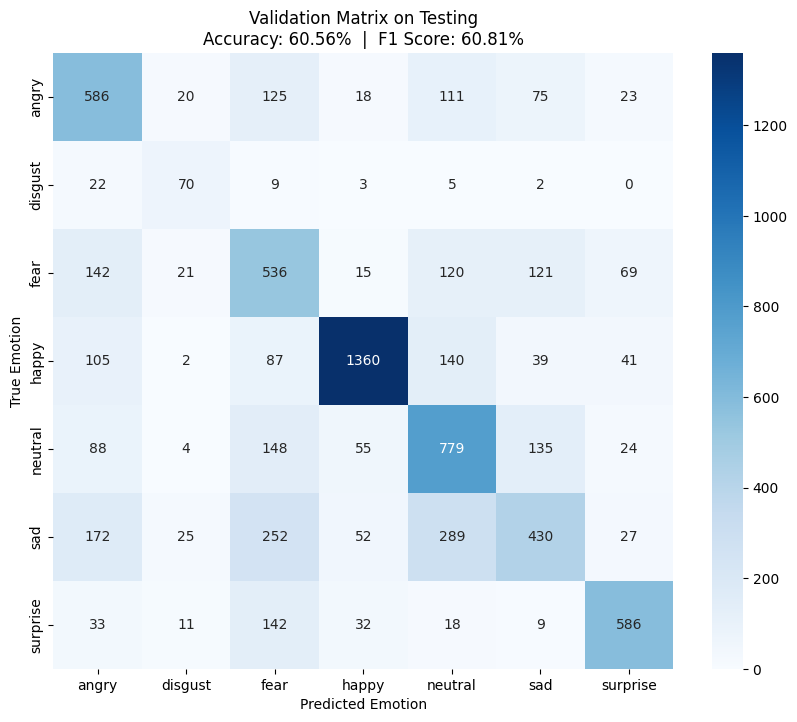

In [9]:
def generate_confusion_matrix(model, X_val, Y_val, title="Validation Confusion Matrix"):
    print(f"\n--- Generating: {title} ---")

    # Forward pass
    predictions = model.predict(X_val)

    # One-hot → integer labels
    y_pred_classes = np.argmax(predictions, axis=1)
    y_true_classes = np.argmax(Y_val, axis=1)

    # Confusion matrix + metrics
    cm = confusion_matrix(y_true_classes, y_pred_classes)
    accuracy = np.mean(y_true_classes == y_pred_classes) * 100
    f1 = f1_score(y_true_classes, y_pred_classes, average='weighted') * 100

    # Plot
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=LABELS, yticklabels=LABELS)
    plt.title(f"{title}\nAccuracy: {accuracy:.2f}%  |  F1 Score: {f1:.2f}%")
    plt.ylabel('True Emotion')
    plt.xlabel('Predicted Emotion')
    plt.show()


generate_confusion_matrix(model, X_train, Y_train, "Validation Matrix on Training")
generate_confusion_matrix(model, X_test, Y_test, "Validation Matrix on Testing")

## 11. Plot Training History

Visualize accuracy and loss curves over epochs to assess convergence and detect overfitting.

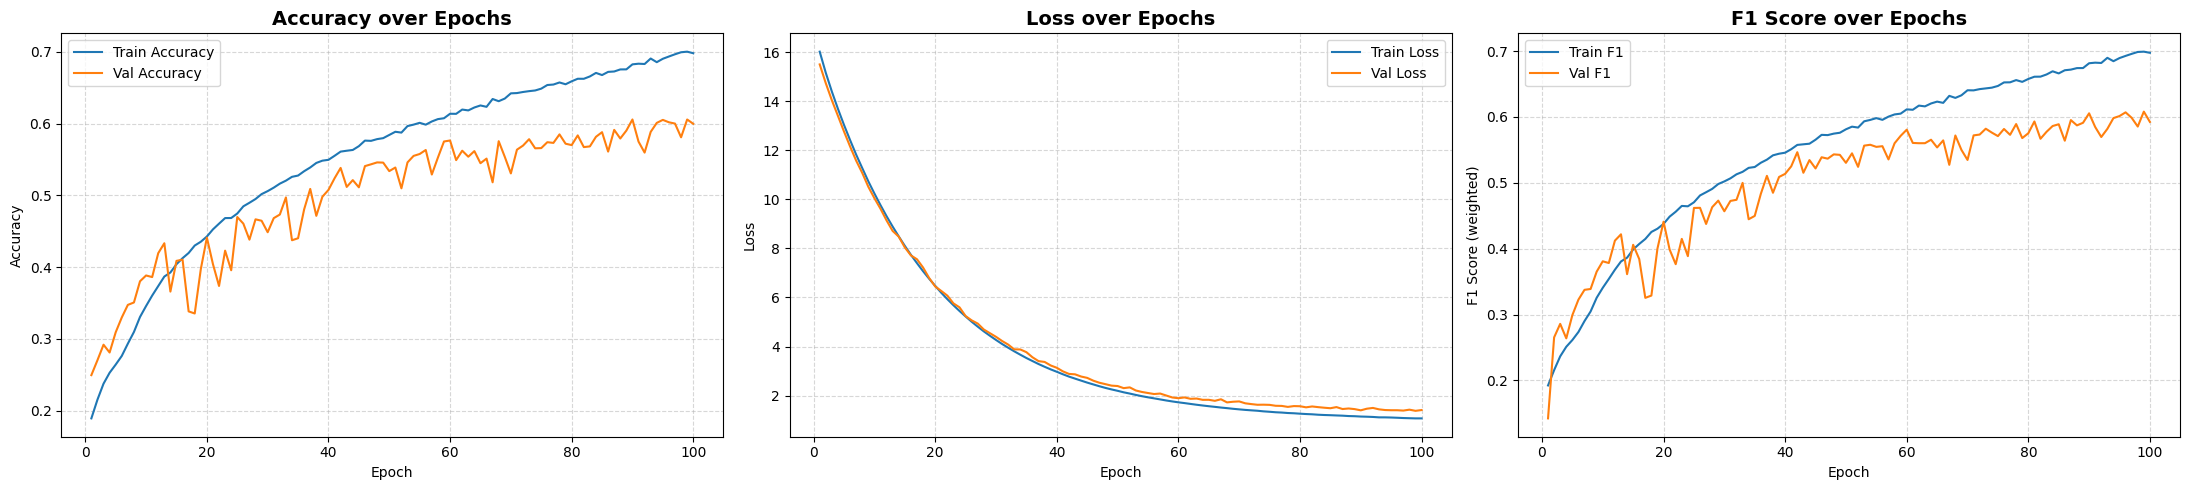

In [10]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 5))

epochs_range = range(1, len(history.history['accuracy']) + 1)

# --- Accuracy ---
ax1.plot(epochs_range, history.history['accuracy'],     label='Train Accuracy')
ax1.plot(epochs_range, history.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Accuracy over Epochs', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# --- Loss ---
ax2.plot(epochs_range, history.history['loss'],     label='Train Loss')
ax2.plot(epochs_range, history.history['val_loss'], label='Val Loss')
ax2.set_title('Loss over Epochs', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

# --- F1 Score ---
ax3.plot(epochs_range, history.history['f1_score'],     label='Train F1')
ax3.plot(epochs_range, history.history['val_f1_score'], label='Val F1')
ax3.set_title('F1 Score over Epochs', fontsize=14, fontweight='bold')
ax3.set_xlabel('Epoch')
ax3.set_ylabel('F1 Score (weighted)')
ax3.legend()
ax3.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()